In [1]:
import sys
import numpy as np


1\. Write a function that converts number representation, bin<->dec<->hex. (Clearly using the corresponding python built-in functions is not fair..)

In [2]:

def getDigit(num, pos):
    if type(num) != str:
        for i in range(pos):
            num //= 10
        return num % 10
    else:
        ch = num[-1-pos]
        if ord(ch) >= ord('A'):
            return ord(ch) - ord('A') + 10
        else:
            return ord(ch) - ord('0')

def getLength(num):
    if num == 0:
        return 1
    
    count = 0
    while num != 0:
        num //= 10
        count += 1
    return count

def numRep_convert(num, init_base, new_base):
    if init_base == new_base:
        return num
    
    if init_base == 10:
        if new_base > 10:
            remainder = ""
        else:
            remainder = []

        while num != 0:
            rem = num % new_base
            # print(f"rem is {num} % {new_base} = {rem}")
            if new_base > 10:
                if (rem >= 10):
                    rem = chr(ord('A') + rem - 10)
                else:
                    rem = chr(ord('0') + rem)
            if type(remainder) == str:
                remainder += rem
            else:
                remainder.append(rem)
            num //= new_base
        # print(remainder)
        if len(remainder) == 0:
            return 0
        if type(remainder) == str:
            res = ""
            for j in range(len(remainder)):
                res += remainder[-1-j]
        else:
            res = 0
            for j in range(len(remainder)):
                res += remainder[j] * 10**j
        return res
    else:
        # convert to 10
        newnum = 0
        length = 0
        if type(num) == str:
            length = len(num)
        else:
            # length = max(int(np.log10(num) / np.log10(init_base)), 1)
            length = getLength(num)
            # print(f"DEBUG: length is {length}")
        for i in range(length):
            dig = getDigit(num, i)
            # print(dig)
            newnum += dig * init_base**i
        # num = newnum
        newnum = int(newnum)
        return numRep_convert(newnum, 10, new_base)

# test
# numRep_convert(1101, 2, new_base=10)
for i in range(1, 50):
    num = i
    print(f"dec: {num} to\t bin: {numRep_convert(num, 10, 2)}, hex: {numRep_convert(num, 10, 16)}")
    num = numRep_convert(i, 10, 2)
    print(f"bin: {num} to\t dec: {numRep_convert(num, 2, 10)}, hex: {numRep_convert(num, 2, 16)}")
    num = numRep_convert(i, 10, 16)
    print(f"hex: {num} to\t bin: {numRep_convert(num, 16, 2)}, dec: {numRep_convert(num, 16, 10)}")
    print()

dec: 1 to	 bin: 1, hex: 1
bin: 1 to	 dec: 1, hex: 1
hex: 1 to	 bin: 1, dec: 1

dec: 2 to	 bin: 10, hex: 2
bin: 10 to	 dec: 2, hex: 2
hex: 2 to	 bin: 10, dec: 2

dec: 3 to	 bin: 11, hex: 3
bin: 11 to	 dec: 3, hex: 3
hex: 3 to	 bin: 11, dec: 3

dec: 4 to	 bin: 100, hex: 4
bin: 100 to	 dec: 4, hex: 4
hex: 4 to	 bin: 100, dec: 4

dec: 5 to	 bin: 101, hex: 5
bin: 101 to	 dec: 5, hex: 5
hex: 5 to	 bin: 101, dec: 5

dec: 6 to	 bin: 110, hex: 6
bin: 110 to	 dec: 6, hex: 6
hex: 6 to	 bin: 110, dec: 6

dec: 7 to	 bin: 111, hex: 7
bin: 111 to	 dec: 7, hex: 7
hex: 7 to	 bin: 111, dec: 7

dec: 8 to	 bin: 1000, hex: 8
bin: 1000 to	 dec: 8, hex: 8
hex: 8 to	 bin: 1000, dec: 8

dec: 9 to	 bin: 1001, hex: 9
bin: 1001 to	 dec: 9, hex: 9
hex: 9 to	 bin: 1001, dec: 9

dec: 10 to	 bin: 1010, hex: A
bin: 1010 to	 dec: 10, hex: A
hex: A to	 bin: 1010, dec: 10

dec: 11 to	 bin: 1011, hex: B
bin: 1011 to	 dec: 11, hex: B
hex: B to	 bin: 1011, dec: 11

dec: 12 to	 bin: 1100, hex: C
bin: 1100 to	 dec: 12, hex: C

2\. Write a function that converts a 32 bit word into a single precision floating point (i.e. interprets the various bits as sign, mantissa and exponent)

In [3]:
def float32(num):
    sign = getDigit(num, 31) == 1
    expon = 0
    for i in range(8):
        # print(getDigit(num, 23 + 1))
        expon += getDigit(num, 23 + i) * 2**i
    mantissa = 0
    for i in range(23):
        # print(getDigit(num, 22-i))
        mantissa += getDigit(num, 22-i) * 2**(-i-1)
    print(f"sign = {sign}\nexpon = {expon}\nmantissa = {mantissa}")
    
    if expon == 0 and mantissa == 0:
        return 0
    if expon == 255:
        if mantissa > 0:
            return np.nan
        if sign:
            return -np.inf
        else:
            return np.inf
    num = (1 + mantissa) * 2**(expon-127)
    if sign:
        num *= -1
    return num

print(numRep_convert(num=11111111, init_base=2, new_base=10))
float32("01111111100000000000000000000001")

255
sign = False
expon = 255
mantissa = 1.1920928955078125e-07


nan

3\. Write a program to determine the underflow and overflow limits (within a factor of 2) for python on your computer. 

**Tips**: define two variables inizialized to 1 and halve/double them enough time to exceed the under/over-flow limits  

In [4]:
import queue

def getOFlim():
    var = 1.0
    count = 0
    mem = queue.SimpleQueue()
    while var > 0 and not np.isinf(var):
        var *= 2
        count += 1
        mem.put(f"count = {count}...  var = {var:.5e} = 2^{np.log2(var)} ")
        if count > 5:
            mem.get()
        if count > 50000:
            break
    while not mem.empty():
        print(mem.get())
    return count

getOFlim()

print(f"sys says OFlim is {sys.float_info.max} = 2^{np.log2(sys.float_info.max)}")

def getUFlim():
    var = 1.0
    count = 0
    mem = queue.SimpleQueue()
    while var > 0 and not np.isinf(var):
        var /= 2
        count += 1
        mem.put(f"count = {count}...  var = {var:.5e} = 2^{np.log2(var)} ")
        if count > 100:
            mem.get()
        if count > 50000:
            break
    while not mem.empty():
        print(mem.get())
    return count

getUFlim()

print(f"sys says UFlim is {sys.float_info.min} = 2^{np.log2(sys.float_info.min)}")

count = 1020...  var = 1.12356e+307 = 2^1020.0 
count = 1021...  var = 2.24712e+307 = 2^1021.0 
count = 1022...  var = 4.49423e+307 = 2^1022.0 
count = 1023...  var = 8.98847e+307 = 2^1023.0 
count = 1024...  var = inf = 2^inf 
sys says OFlim is 1.7976931348623157e+308 = 2^1024.0
count = 976...  var = 1.56576e-294 = 2^-976.0 
count = 977...  var = 7.82878e-295 = 2^-977.0 
count = 978...  var = 3.91439e-295 = 2^-978.0 
count = 979...  var = 1.95720e-295 = 2^-979.0 
count = 980...  var = 9.78598e-296 = 2^-980.0 
count = 981...  var = 4.89299e-296 = 2^-981.0 
count = 982...  var = 2.44649e-296 = 2^-982.0 
count = 983...  var = 1.22325e-296 = 2^-983.0 
count = 984...  var = 6.11624e-297 = 2^-984.0 
count = 985...  var = 3.05812e-297 = 2^-985.0 
count = 986...  var = 1.52906e-297 = 2^-986.0 
count = 987...  var = 7.64530e-298 = 2^-987.0 
count = 988...  var = 3.82265e-298 = 2^-988.0 
count = 989...  var = 1.91132e-298 = 2^-989.0 
count = 990...  var = 9.55662e-299 = 2^-990.0 
count = 991...

/tmp/ipykernel_47848/642138811.py:30: RuntimeWarning: divide by zero encountered in log2
  mem.put(f"count = {count}...  var = {var:.5e} = 2^{np.log2(var)} ")


4\. Write a program to determine the machine precision

**Tips**: define a new variable by adding a smaller and smaller value (proceeding similarly to prob. 2) to an original variable and check the point where the two are the same 

In [5]:
def findEPS():
    one = 1
    eps = 1
    count = -1
    while one != one + eps:
        count += 1
        eps /= 2
    return count

foundEPSexp = findEPS()
foundEPS = 2**-foundEPSexp
print(f"eps is 2^-{foundEPSexp} = {foundEPS}")
print(f"sys says eps is {sys.float_info.epsilon} = 2^{np.log2(sys.float_info.epsilon)}")

eps is 2^-52 = 2.220446049250313e-16
sys says eps is 2.220446049250313e-16 = 2^-52.0


5\. Write a function that takes in input three parameters $a$, $b$ and $c$ and prints out the two solutions to the quadratic equation $ax^2+bx+c=0$ using the standard formula:
$$
x=\frac{-b\pm\sqrt{b^2-4ac}}{2a}
$$

(a) use the program to compute the solution for $a=0.001$, $b=1000$ and $c=0.001$

(b) re-express the standard solution formula by multiplying top and bottom by $-b\mp\sqrt{b^2-4ac}$ and again find the solution for $a=0.001$, $b=1000$ and $c=0.001$. How does it compare with what previously obtained? Why?

(c) write a function that compute the roots of a quadratic equation accurately in all cases

quadrEq0 gives (-9.999894245993346e-07, -999999.999999)
quadrEq1 gives (-9.999894245993346e-07, -999999.9999990001)
quadrEq2 gives (-1.000000000001e-06, -1000010.5755125057)
quadrEqTry gives (-1.0000462680181954e-06, -999999.999999)
quadrEqBest gives (-1.000000000001e-06, -999999.999999)


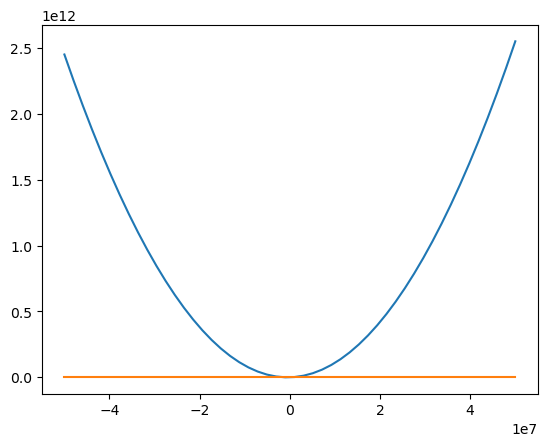

In [17]:
import matplotlib.pyplot as plt

def quadrEq0(a, b, c):
    x0 = (-b + np.sqrt(b*b - 4*a*c)) / (2*a)
    x1 = (-b - np.sqrt(b*b - 4*a*c)) / (2*a)
    return x0, x1

def quadrEq1(a, b, c):
    x0 = ((-b + np.sqrt(b*b - 4*a*c)) * (-b - np.sqrt(b*b - 4*a*c))) / (2*a * (-b - np.sqrt(b*b - 4*a*c)))
    x1 = ((-b - np.sqrt(b*b - 4*a*c)) * (-b + np.sqrt(b*b - 4*a*c))) / (2*a * (-b + np.sqrt(b*b - 4*a*c)))
    return x0, x1

def quadrEq2(a, b, c):
    x0 = 2*c / (-b - np.sqrt(b*b - 4*a*c))
    x1 = 2*c / (-b + np.sqrt(b*b - 4*a*c))
    return x0, x1

def quadrEqTry(a, b, c):
    temp = 2 * np.sqrt(a) * np.sqrt(c)
    sqrtD = np.sqrt(b + temp) * np.sqrt(b - temp)
    x0 = (-b + sqrtD) / (2 * a)
    x1 = (-b - sqrtD) / (2 * a)
    return x0, x1

def quadrEqBest(a, b, c):
    x0 = 2*c / (-b - np.sqrt(b*b - 4*a*c))
    x1 = (-b - np.sqrt(b*b - 4*a*c)) / (2*a)
    return x0, x1

a = 0.001
b = 1000
c = 0.001
print(f"quadrEq0 gives {quadrEq0(a,b,c)}")
print(f"quadrEq1 gives {quadrEq1(a,b,c)}")
print(f"quadrEq2 gives {quadrEq2(a,b,c)}")
print(f"quadrEqTry gives {quadrEqTry(a,b,c)}")
print(f"quadrEqBest gives {quadrEqBest(a,b,c)}")

x = np.linspace(-5e7, 5e7)
plt.plot(x, a*x*x + b*x + c)
plt.plot(x, np.zeros(x.size))

6\. Write a program that implements the function $f(x)=x(x−1)$

(a) Calculate the derivative of the function at the point $x = 1$ using the derivative definition:

$$
\frac{{\rm d}f}{{\rm d}x} = \lim_{\delta\to0} \frac{f(x+\delta)-f(x)}{\delta}
$$

with $\delta = 10^{−2}$. Calculate the true value of the same derivative analytically and compare with the answer your program gives. The two will not agree perfectly. Why not?

(b) Repeat the calculation for $\delta = 10^{−4}, 10^{−6}, 10^{−8}, 10^{−10}, 10^{−12}$ and $10^{−14}$. How does the accuracy scales with $\delta$?

specialFunc(1) = 0
specialFunc_prime(1) = 1
manual_derivative(specialFunc, 1) = 1.010000000000001


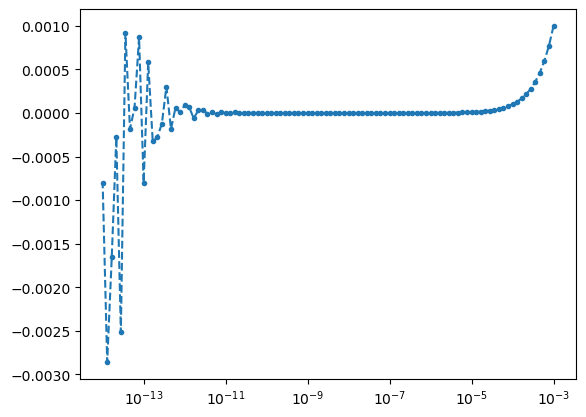

In [7]:
def manual_derivative(func, x, delta = 1e-2):
    return (func(x + delta) - func(x)) / delta

def specialFunc(x):
    return x * (x - 1)

def specialFunc_prime(x):
    return 2*x - 1

print(f"specialFunc(1) = {specialFunc(1)}")
print(f"specialFunc_prime(1) = {specialFunc_prime(1)}")
print(f"manual_derivative(specialFunc, 1) = {manual_derivative(specialFunc, 1)}")

delta = np.logspace(-3, -14, 100)
ref = specialFunc_prime(1)
diff = manual_derivative(specialFunc, 1, delta) - ref
plt.errorbar(delta, diff, marker='.', ls="--")
plt.xscale("log")

7\. Consider the integral of the semicircle of radius 1:
$$
I=\int_{-1}^{1} \sqrt(1-x^2) {\rm d}x
$$
which it's known to be $I=\frac{\pi}{2}=1.57079632679...$.
Alternatively we can use the Riemann definition of the integral:
$$
I=\lim_{N\to\infty} \sum_{k=1}^{N} h y_k 
$$

with $h=2/N$ the width of each of the $N$ slices the domain is divided into and where
$y_k$ is the value of the function at the $k-$th slice.

(a) Write a programe to compute the integral with $N=100$. How does the result compares to the true value?

(b) How much can $N$ be increased if the computation needs to be run in less than a second? What is the gain in running it for 1 minute? 


In [8]:
def manual_integral(func, lb, ub, N=100):
    h = 2/N
    x = np.linspace(lb, ub, N, endpoint=True)
    return h * np.sum(func(x))

def manualmanual_integral(func, lb, ub, N=100):
    h = 2/N
    dx = (ub-lb)/(N-1)
    sum = 0
    for k in range(N):
        sum += func(lb + k * dx)
    return h * sum

def riemFunc(x):
    return np.sqrt(1 - x*x)

print(f"analytical integral of riemFunc = {np.pi / 2}")
print(f"manual_integral(riemFunc, -1, 1) = {manual_integral(riemFunc, -1, 1)}")
print(f"manualmanual_integral(riemFunc, -1, 1) = {manual_integral(riemFunc, -1, 1)}")

analytical integral of riemFunc = 1.5707963267948966
manual_integral(riemFunc, -1, 1) = 1.5534179294048955
manualmanual_integral(riemFunc, -1, 1) = 1.5534179294048955


In [11]:
%%timeit
manual_integral(riemFunc, -1, 1, N=int(1e8))

972 ms ± 55.4 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [12]:
%%timeit
manualmanual_integral(riemFunc, -1, 1, N=int(1e7))

8.78 s ± 167 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [13]:
%%timeit
manualmanual_integral(riemFunc, -1, 1, N=int(1e8))

1min 28s ± 3.32 s per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [14]:
manualmanual_integral(riemFunc, -1, 1, N=int(1e8))

1.5707963110855314

In [18]:
1.5707963110855314 - 1.5534179294048955

0.01737838168063588

In [19]:
(1.5707963110855314 - 1.5534179294048955) / (np.pi / 2)

0.01106342138964336